# Sales Forecasting - Superstore Dataset
End-to-end notebook: EDA -> Feature Engineering -> Model Benchmarking -> Final Model -> Forecast


## 1. Imports & Config

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Shared logic also used by app.py - keeping this as the single source of
# truth means training and the app can never silently drift apart.
from sales_forecast_utils import (
    load_and_aggregate, add_features, get_feature_cols, recursive_forecast,
)

%matplotlib inline

DATA_PATH = "C:/projects/sales_forecasting/Superstore.csv"   # update path if needed
TEST_SIZE_DAYS = 90
FORECAST_HORIZON_DAYS = 30


## 2. Load Raw Data\n`load_and_aggregate` comes from `sales_forecast_utils.py` - the same function the Streamlit app calls, so the daily series is built identically in both places.

In [3]:
raw, daily = load_and_aggregate(DATA_PATH)

print(raw.shape)
raw.head()


(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   str           
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [5]:
raw.isnull().sum()


Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

## 3. Exploratory Data Analysis
This dataset is **transaction-level** (one row per order line item), so we first look at it raw, then aggregate to a daily sales series for forecasting.

In [6]:
print("Date range:", raw["Order Date"].min(), "to", raw["Order Date"].max())
print("Unique order dates:", raw["Order Date"].nunique())
print("Unique customers:", raw["Customer ID"].nunique())
print("Categories:", raw["Category"].unique())


Date range: 2014-01-03 00:00:00 to 2017-12-30 00:00:00
Unique order dates: 1237
Unique customers: 793
Categories: <ArrowStringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str


In [7]:
raw["Sales"].describe()


count     9994.000000
mean       229.858001
std        623.245101
min          0.444000
25%         17.280000
50%         54.490000
75%        209.940000
max      22638.480000
Name: Sales, dtype: float64

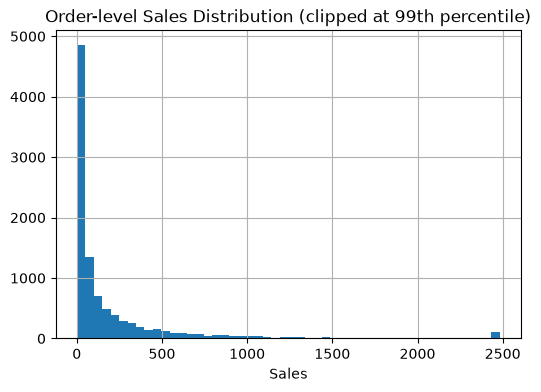

In [8]:
plt.figure(figsize=(6,4))
raw["Sales"].clip(upper=raw["Sales"].quantile(0.99)).hist(bins=50)
plt.title("Order-level Sales Distribution (clipped at 99th percentile)")
plt.xlabel("Sales")
plt.show()


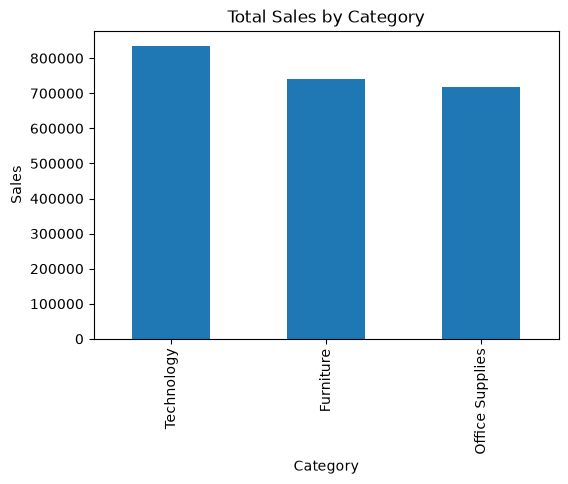

In [9]:
category_sales = raw.groupby("Category")["Sales"].sum().sort_values(ascending=False)
category_sales.plot(kind="bar", figsize=(6,4), title="Total Sales by Category")
plt.ylabel("Sales")
plt.show()


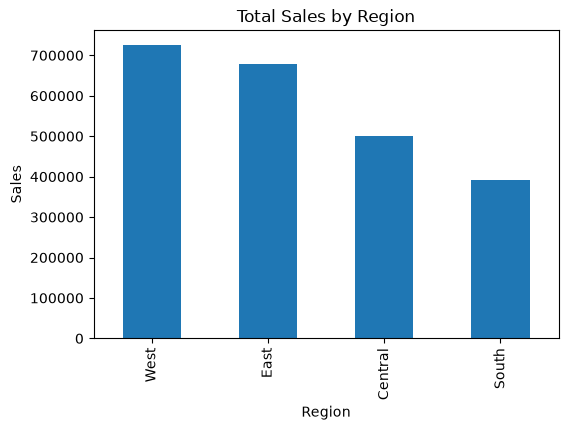

In [10]:
region_sales = raw.groupby("Region")["Sales"].sum().sort_values(ascending=False)
region_sales.plot(kind="bar", figsize=(6,4), title="Total Sales by Region")
plt.ylabel("Sales")
plt.show()


### Daily sales series
`daily` (already built by `load_and_aggregate` above) has one row per calendar day, with days that had no orders filled in as 0 sales.

In [11]:
print(daily.shape)
daily.head()


(1458, 2)


,date,sales
0,2014-01-03,16.448
1,2014-01-04,288.060
2,2014-01-05,19.536
3,2014-01-06,4407.100
4,2014-01-07,87.158


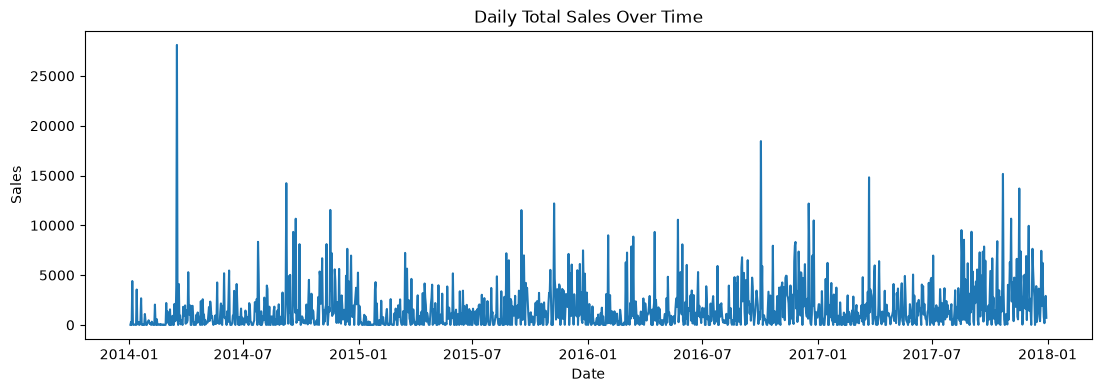

In [12]:
plt.figure(figsize=(13,4))
plt.plot(daily["date"], daily["sales"])
plt.title("Daily Total Sales Over Time")
plt.xlabel("Date"); plt.ylabel("Sales")
plt.show()


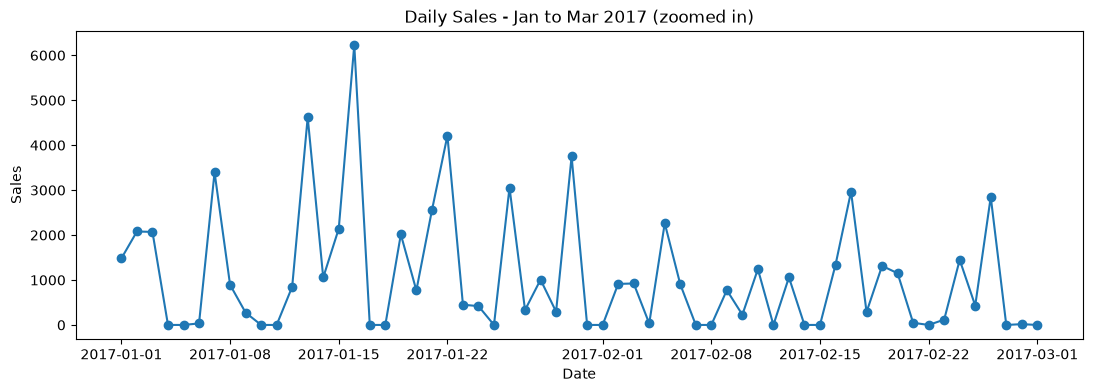

In [13]:
# Zoom into a shorter window to see weekly pattern more clearly
window = daily[(daily["date"] >= "2017-01-01") & (daily["date"] <= "2017-03-01")]
plt.figure(figsize=(13,4))
plt.plot(window["date"], window["sales"], marker="o")
plt.title("Daily Sales - Jan to Mar 2017 (zoomed in)")
plt.xlabel("Date"); plt.ylabel("Sales")
plt.show()


In [14]:
# Fraction of days with zero sales, and volatility check
zero_days = (daily["sales"] == 0).mean() * 100
print(f"% of days with zero sales: {zero_days:.1f}%")
print(daily["sales"].describe())


% of days with zero sales: 15.2%
count     1458.000000
mean      1575.583580
std       2225.547339
min          0.000000
25%        121.927500
50%        823.476000
75%       2083.569500
max      28106.716000
Name: sales, dtype: float64


**Observation:** daily sales are noisy — some days have \$0 in sales, and the standard deviation is roughly as large as the mean. This tells us to expect modest forecast accuracy from any model, and to prefer MAE/RMSE over MAPE (which blows up near zero-sales days).

## 4. Feature Engineering
`add_features` also comes from `sales_forecast_utils.py`. We add calendar features (day of week, month, etc.) and lag/rolling features (sales N days ago, rolling averages) so the model can learn from recent history and seasonality - using the exact same function the app uses at prediction time.

In [15]:
featured = add_features(daily).dropna().reset_index(drop=True)
feature_cols = get_feature_cols(featured)

print("Feature columns:", feature_cols)
featured.head()


Feature columns: ['day_of_week', 'month', 'quarter', 'is_weekend', 'is_month_start', 'is_month_end', 'lag_1', 'lag_7', 'lag_14', 'lag_30', 'rolling_mean_7', 'rolling_std_7', 'rolling_mean_14', 'rolling_std_14', 'rolling_mean_30', 'rolling_std_30']


,date,sales,day_of_week,month,quarter,is_weekend,is_month_start,is_month_end,lag_1,lag_7,lag_14,lag_30,rolling_mean_7,rolling_std_7,rolling_mean_14,rolling_std_14,rolling_mean_30,rolling_std_30
0,2014-02-02,211.646,6,2,1,1,0,0,468.900,1097.250,378.594,16.448,361.130571,373.119158,403.689000,721.237006,490.193167,1084.430234
1,2014-02-03,97.112,0,2,1,0,0,0,211.646,426.670,2673.870,288.060,234.615714,184.272985,391.764143,723.061683,496.699767,1082.072772
2,2014-02-04,134.384,1,2,1,0,0,0,97.112,3.928,25.248,19.536,187.536000,168.446888,207.710000,303.971952,490.334833,1083.902392
3,2014-02-05,0.000,2,2,1,0,0,0,134.384,0.000,0.000,4407.100,206.172571,151.067374,215.505429,300.310080,494.163100,1082.383979
4,2014-02-06,330.512,3,2,1,0,0,0,0.000,240.500,46.020,87.158,206.172571,151.067374,215.505429,300.310080,347.259767,793.525559


## 5. Train / Test Split
Time series data must be split **chronologically**, never shuffled randomly, or the model would learn from the future to predict the past.

In [16]:
cutoff = featured["date"].max() - pd.Timedelta(days=TEST_SIZE_DAYS)
train = featured[featured["date"] <= cutoff]
test = featured[featured["date"] > cutoff]

X_train, y_train = train[feature_cols], train["sales"]
X_test, y_test = test[feature_cols], test["sales"]

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train dates:", train["date"].min().date(), "to", train["date"].max().date())
print("Test dates:", test["date"].min().date(), "to", test["date"].max().date())


Train: (1338, 16) Test: (90, 16)
Train dates: 2014-02-02 to 2017-10-01
Test dates: 2017-10-02 to 2017-12-30


## 6. Model Benchmarking
We don't assume any one model wins — we train several under identical conditions and compare on the same holdout set. `xgboost`/`lightgbm` are included if installed; otherwise they're skipped automatically.

In [17]:
candidates = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=8, random_state=42),
    "Gradient Boosting (sklearn)": GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42),
}

try:
    import xgboost as xgb
    candidates["XGBoost"] = xgb.XGBRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, random_state=42)
except ImportError:
    print("xgboost not installed - run: pip install xgboost")

try:
    import lightgbm as lgb
    candidates["LightGBM"] = lgb.LGBMRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=6, random_state=42, verbose=-1)
except ImportError:
    print("lightgbm not installed - run: pip install lightgbm")

print("Models to benchmark:", list(candidates.keys()))


xgboost not installed - run: pip install xgboost
lightgbm not installed - run: pip install lightgbm
Models to benchmark: ['Linear Regression', 'Ridge Regression', 'Random Forest', 'Gradient Boosting (sklearn)']


In [18]:
results = {}
fitted_models = {}

def evaluate(name, model, preds):
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    results[name] = {"MAE": mae, "RMSE": rmse}
    fitted_models[name] = model
    print(f"{name:30s} -> MAE: {mae:8.2f}  RMSE: {rmse:8.2f}")

# Baselines first, for context
evaluate("Naive (lag_1)", None, X_test["lag_1"])
evaluate("Moving Avg (7d)", None, X_test["rolling_mean_7"])

for name, model in candidates.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    evaluate(name, model, preds)


Naive (lag_1)                  -> MAE:  3121.40  RMSE:  4056.09
Moving Avg (7d)                -> MAE:  2537.62  RMSE:  3307.36
Linear Regression              -> MAE:  2173.69  RMSE:  3118.94
Ridge Regression               -> MAE:  2173.83  RMSE:  3118.39
Random Forest                  -> MAE:  2106.34  RMSE:  2962.42
Gradient Boosting (sklearn)    -> MAE:  2284.96  RMSE:  3189.20


In [19]:
results_df = pd.DataFrame(results).T.sort_values("RMSE")
results_df


,MAE,RMSE
Random Forest,2106.337954,2962.418925
Ridge Regression,2173.831178,3118.394480
Linear Regression,2173.687732,3118.937505
Gradient Boosting (sklearn),2284.959723,3189.199573
Moving Avg (7d),2537.615614,3307.363813
Naive (lag_1),3121.396671,4056.093675


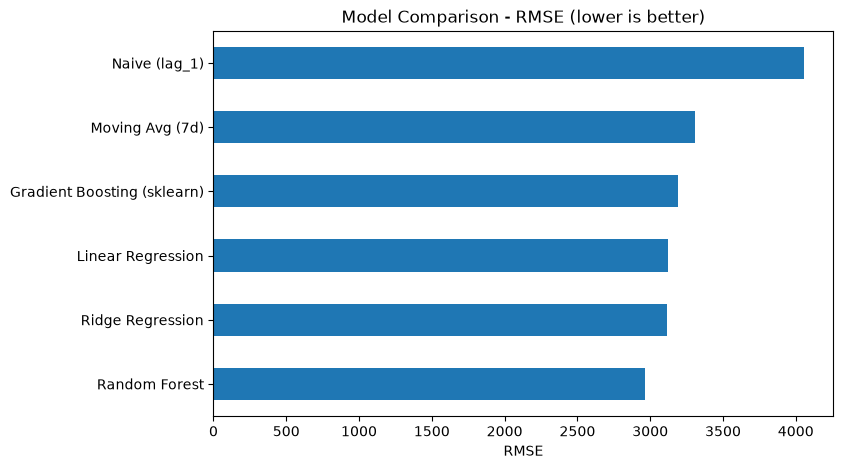

Best model on this holdout set: Random Forest


In [20]:
results_df["RMSE"].sort_values().plot(kind="barh", figsize=(8,5), title="Model Comparison - RMSE (lower is better)")
plt.xlabel("RMSE")
plt.show()

best_name = results_df["RMSE"].idxmin()
print("Best model on this holdout set:", best_name)


**Note:** all models land fairly close together and only modestly beat the naive baseline — a sign that daily sales here are inherently noisy. Don't over-trust a small RMSE gap between two models as a meaningful difference; re-run with a different test window to check how stable the ranking is.

## 7. Feature Importance (for tree-based winner)

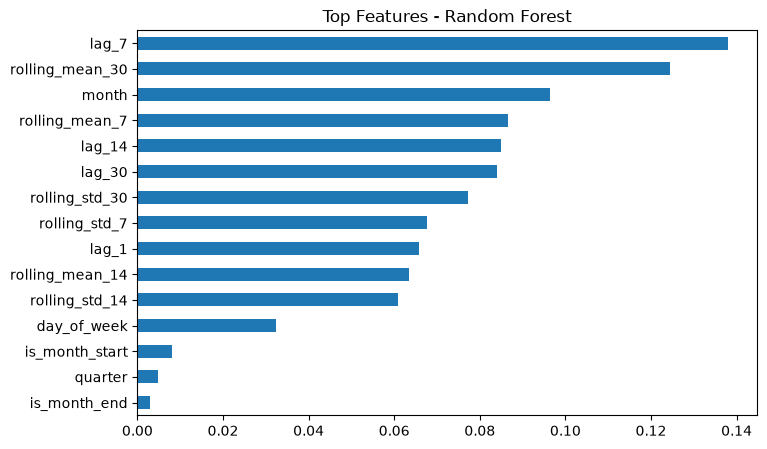

In [21]:
best_model = fitted_models.get(best_name)

if best_model is not None and hasattr(best_model, "feature_importances_"):
    importance = pd.Series(best_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
    importance.head(15).sort_values().plot(kind="barh", figsize=(8,5), title=f"Top Features - {best_name}")
    plt.show()
    importance.head(10)
else:
    print(f"{best_name} has no feature_importances_ attribute (likely a linear model).")


## 8. Retrain Best Model on Full Data & Save

In [22]:
best_model_class = type(candidates[best_name])
best_params = candidates[best_name].get_params()

X_full, y_full = featured[feature_cols], featured["sales"]
final_model = best_model_class(**best_params)
final_model.fit(X_full, y_full)

joblib.dump(final_model, "final_model.pkl")
print(f"Final model ({best_name}) retrained on full data and saved to final_model.pkl")


Final model (Random Forest) retrained on full data and saved to final_model.pkl


## 9. Forecast Future Sales
Since future dates don't have real lag/rolling values yet, we forecast **recursively**: predict one day, append it to history, then use it to compute the next day's lag features, and so on. `recursive_forecast` is the same shared function `app.py` calls - this is what keeps the notebook's forecast and the app's forecast consistent.

In [23]:
future_df = recursive_forecast(final_model, daily, feature_cols, FORECAST_HORIZON_DAYS)
future_df.to_csv("future_forecast.csv", index=False)
future_df.head(10)


,date,sales
0,2017-12-31,2999.837790
1,2018-01-01,2690.716438
2,2018-01-02,1074.436108
3,2018-01-03,992.075997
4,2018-01-04,1148.276668
5,2018-01-05,1248.567423
6,2018-01-06,1094.091370
7,2018-01-07,2001.044765
8,2018-01-08,1263.982467
9,2018-01-09,971.169381


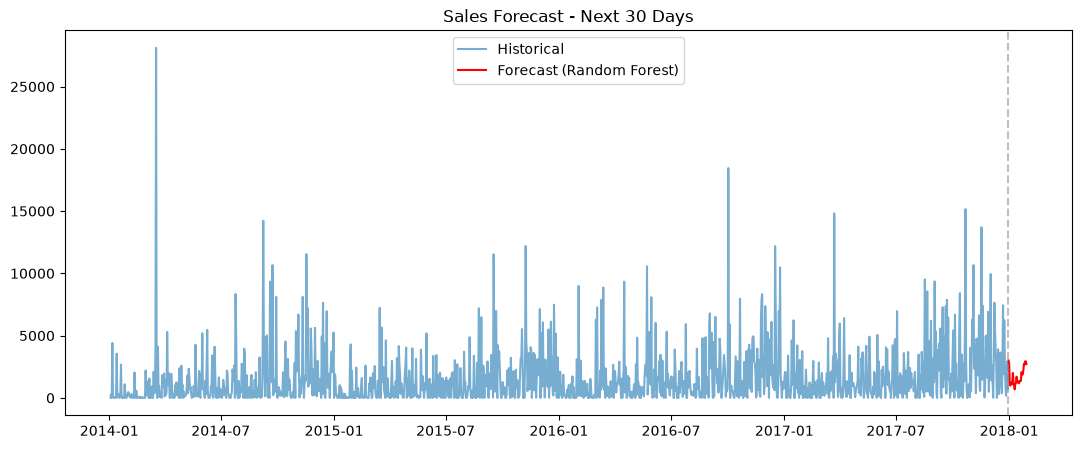

In [24]:
plt.figure(figsize=(13,5))
plt.plot(daily["date"], daily["sales"], label="Historical", alpha=0.6)
plt.plot(future_df["date"], future_df["sales"], label=f"Forecast ({best_name})", color="red")
plt.axvline(daily["date"].max(), linestyle="--", color="gray", alpha=0.5)
plt.legend()
plt.title(f"Sales Forecast - Next {FORECAST_HORIZON_DAYS} Days")
plt.show()


## 10. Summary
- Aggregated ~10K transactions into a daily sales series
- Engineered calendar + lag + rolling features
- Benchmarked 6 models on an identical chronological holdout
- Auto-selected the best performer, retrained on full history, and forecasted forward

**Next steps to consider:** try weekly aggregation to reduce noise, install `xgboost`/`lightgbm` for a wider model comparison, and validate the ranking on a second holdout window before trusting it in production.

### How this links to the Streamlit app
Running this notebook top-to-bottom regenerates `final_model.pkl`. `app.py` loads that exact file on startup and reuses `sales_forecast_utils.py` for feature engineering and forecasting - so there is nothing else to "wire up" manually. The workflow is:
1. Edit/retrain in this notebook whenever you have new data or want to try a new model
2. Run all cells -> `final_model.pkl` is overwritten
3. Restart (or just rerun) `streamlit run app.py` -> it picks up the new model automatically (the `@st.cache_resource` decorator caches it per server session, not forever)